In [4]:
import sympy as sp
import numpy as np
import matplotlib.pyplot as plt

In [146]:
x = sp.symbols('x')
r_a, r_s, x_c = sp.symbols('r_a r_s x_c', real=True)

S = 1 / (1 + sp.exp(x_c - x))

F = ((1 - S)*r_a + S*r_s) * x

fixed_eq = sp.Eq(x, F)
fixed_eq

Eq(x, x*(r_a*(1 - 1/(exp(-x + x_c) + 1)) + r_s/(exp(-x + x_c) + 1)))

Стационарные точки

In [130]:
solutions = sp.solve(fixed_eq, x)
solutions

[0, x_c + log((1 - r_a)/(r_s - 1))]

Есть нулевая и ненулевая:

Производная, чтобы туда подставить стационарные точки

In [147]:
dF = sp.diff(F, x)
print(dF)
dF

r_a*(1 - 1/(exp(-x + x_c) + 1)) + r_s/(exp(-x + x_c) + 1) + x*(-r_a*exp(-x + x_c)/(exp(-x + x_c) + 1)**2 + r_s*exp(-x + x_c)/(exp(-x + x_c) + 1)**2)


r_a*(1 - 1/(exp(-x + x_c) + 1)) + r_s/(exp(-x + x_c) + 1) + x*(-r_a*exp(-x + x_c)/(exp(-x + x_c) + 1)**2 + r_s*exp(-x + x_c)/(exp(-x + x_c) + 1)**2)

Устойчивость нулевой точке

In [152]:
dFx_stac0 = dF.subs(x, solutions[0])
stability_condition0 = sp.Abs(dFx_stac0) < 1
stability_condition0.simplify()

Abs(r_a*exp(x_c) + r_s)/(exp(x_c) + 1) < 1

Устойчивость в ненулевой точке

In [154]:
dFx_stac = sp.simplify(dF.subs(x, solutions[1]))
stability_condition = sp.Abs(dFx_stac) < 1
stability_condition.simplify()

Abs((-r_a*(r_s - 1) + r_s*(r_a - 1) + (r_a - 1)*(r_s - 1)*(x_c + log(-(r_a - 1)/(r_s - 1))))/(r_a - r_s)) < 1

In [132]:
import matplotlib.colors as mcolors
import matplotlib.cm as cm

def f(x, xc):
    return 1.0 / (1.0 + np.exp(xc - x))


# ===== СТАЦИОНАРНАЯ ТОЧКА =====
def x_star(ra, rs, xc):
    """
    x* = xc - ln((rs - 1)/(1 - ra)), если (rs - 1)/(1 - ra) > 0
    """
    x = np.full_like(ra, np.nan, dtype=float)
    with np.errstate(divide="ignore", invalid="ignore"):
        ratio = (rs - 1.0) / (1.0 - ra)
        mask = ratio > 0
        x[mask] = xc - np.log(ratio[mask])
    return x


# ===== ПРОИЗВОДНАЯ ОТОБРАЖЕНИЯ В x* =====
def Fprime_at_xstar(r_a, r_s, x_c, x):
    ex = np.exp(-x + x_c)
    return r_a*(1 - 1/(ex + 1)) + r_s/(ex + 1) + x*(-r_a*ex/(ex + 1)**2 + r_s*ex/(ex + 1)**2)


# ===== ОДИН ГРАФИК =====
def plot_single(ax, xc, ra_range, rs_range, n, xstar_levels):

    ra = np.linspace(*ra_range, n)
    rs = np.linspace(*rs_range, n)
    RA, RS = np.meshgrid(ra, rs)

    Xs = x_star(RA, RS, xc)
    dF = Fprime_at_xstar(RA, RS, xc, Xs)
    dF0 = Fprime_at_xstar(RA, RS, xc, 0)

    # ===== ОБЛАСТЬ |F'| < 1 =====
    stable = (dF > -1) & (dF < 1)
    stable0 = (dF0 > -1) & (dF0 < 1)
    
    rg = ax.contourf(
        RA, RS, stable0,
        levels=[0.5, 1],
        colors=["#e5ccff"],
        alpha=0.45
    )
    ax.clabel(
        rg,
        fmt={0.5: "|F`|<1"},
        inline=False,
        fontsize=8
        )

    g = ax.contourf(
        RA, RS, stable,
        levels=[0.5, 1],
        colors=["#ccffe5"],
        alpha=0.85
    )
    ax.clabel(
        g,
        fmt={0.5: "|F`|<1"},
        inline=False,
        fontsize=8
        )
    


    # ===== ГРАНИЦЫ УСТОЙЧИВОСТИ =====
    b = ax.contour(
        RA, RS, dF,
        levels=[-1],
        colors="blue",
        linestyles="dashed",
        linewidths=1.8
    )
    ax.clabel(
        b,
        fmt={-1: "F`=-1"},
        inline=True,
        fontsize=8
        )

    r = ax.contour(
        RA, RS, dF,
        levels=[1],
        colors="red",
        linestyles="dashed",
        linewidths=1.8
    )
    ax.clabel(
        r,
        fmt={1: "F`=1"},
        inline=True,
        fontsize=8
        )

    # ===== СТАЦИОНАРНЫЕ КРИВЫЕ x* =====
    finite = np.isfinite(Xs)
    if np.any(finite):
        xmin, xmax = np.nanmin(Xs), np.nanmax(Xs)
        cmap = plt.get_cmap("coolwarm")
        for num, lvl in enumerate(xstar_levels):
            if xmin < lvl < xmax:
                t = num / max(lvl - 1, 1)   # нормировка [0,1]
                color = cmap(t)
                cs = ax.contour(
                    RA, RS, Xs,
                    levels=[lvl],
                    colors=[color],
                    linewidths=2
                )
                ax.clabel(
                    cs,
                    fmt={lvl: rf"{lvl}"},
                    inline=True,
                    fontsize=8
                )
                

    ax.set_title(rf"$x_c = {xc}$")
    ax.set_xlabel(r"$r_a$")
    ax.set_ylabel(r"$r_s$")
    ax.grid(True, linestyle=":", alpha=0.6)


def plot_stability_grid(
    xc_list,
    ra_range=(0.0, 2.0),
    rs_range=(0.0, 4.0),
    n=400,
    xstar_levels=(2, 5, 10),
    ncols=3,
    figsize=(20, 4)
):

    nrows = int(np.ceil(len(xc_list) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=figsize)
    axes = np.atleast_1d(axes).flatten()

    for ax, xc in zip(axes, xc_list):
        plot_single(ax, xc, ra_range, rs_range, n, xstar_levels)

    for i in range(len(xc_list), len(axes)):
        axes[i].axis("off")

    plt.tight_layout()
    plt.show()

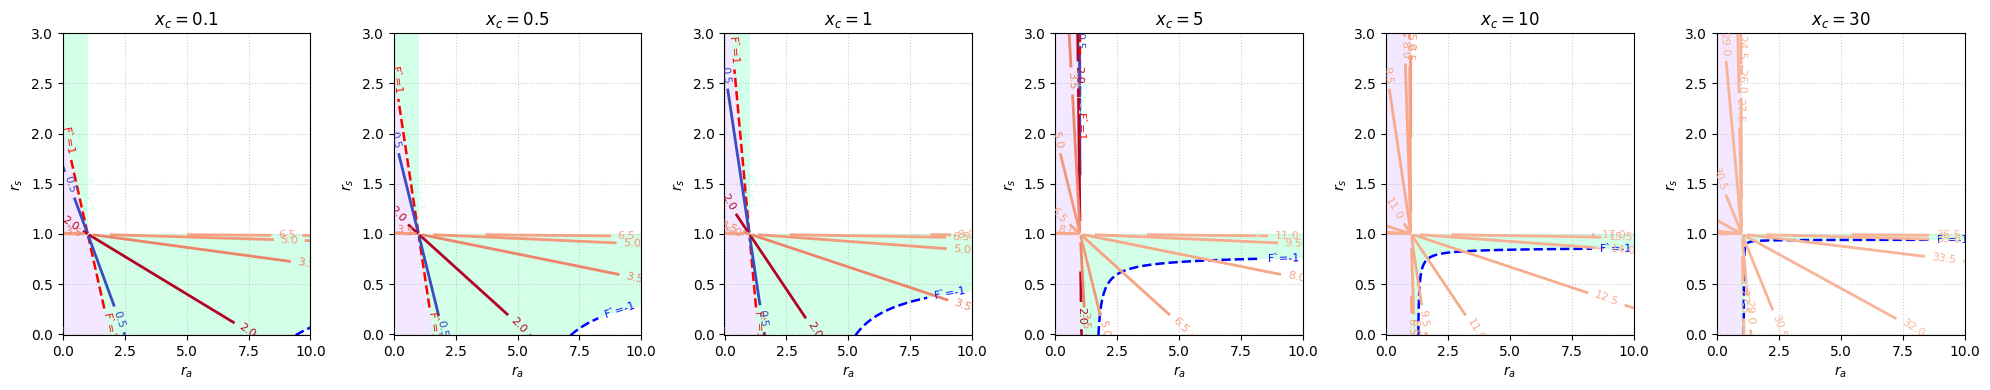

In [163]:
xc_values = [ 0.1, 0.5, 1, 5, 10, 30]
plot_stability_grid(
    xc_values,
    ra_range=(-0.01, 10),
    rs_range=(-0.01, 3),
    xstar_levels=[0.5 + 1.5*i for i in range(50)],
    ncols=6
)

In [204]:
def Fun(x, r_a, r_s, xc):
    return x*(r_a*(1 - 1/(1 + np.exp(xc - x)))
                + r_s/((1 + np.exp(xc - x))))

def r_bifurcation_ax(ax, xc_val, x_start, r_a_val, r_s_max = 2):
    P = np.linspace(0, r_s_max, 100)
    r_a = r_a_val
    xc = xc_val
    R = []
    X = []
    for r_s in P:
        x = 0.01 + 0.01*np.random.rand()
        for n in range(3025):
            x = Fun(x, r_a, r_s, xc)
            if not np.isfinite(x):
                break
        for n in range(200):
            x = Fun(x, r_a, r_s, xc)
            if not np.isfinite(x):
                break
            R.append(r_s)
            X.append(x)
    ax.plot(R, X, ls='None', marker=',')
    ax.set_title(f'$x_c={xc_val},\\;r_a={r_a}$')
    ax.set_xlabel('$r_s$')
    ax.set_ylabel('$x$')

In [205]:
fig, axes = plt.subplots(1, 3, figsize=(8, 4))

xc = 1
r_a_values  = [1, 2, 5]

for j, r_a in enumerate(r_a_values):
    r_bifurcation_ax(axes[j], xc, 4, r_a)

plt.tight_layout()
plt.show()

D:\Temp\ipykernel_11256\221894887.py:2: RuntimeWarning: overflow encountered in scalar multiply
  return x*(r_a*(1 - 1/(1 + np.exp(xc - x)))


ValueError: arange: cannot compute length

Error in callback <function _draw_all_if_interactive at 0x00000223E30CF240> (for post_execute), with arguments args (),kwargs {}:


ValueError: arange: cannot compute length

ValueError: arange: cannot compute length

<Figure size 800x400 with 3 Axes>

In [136]:
def plot_3d_stationary_surface(
    xc,
    ra_range=(0, 2),
    rs_range=(0, 4),
    n=200
):
    ra = np.linspace(*ra_range, n)
    rs = np.linspace(*rs_range, n)
    RA, RS = np.meshgrid(ra, rs)

    Xs = x_star(RA, RS, xc)
    dF = Fprime_at_xstar(RA, RS, xc, Xs)

    valid = np.isfinite(Xs)
    stable = valid & (np.abs(dF) < 1)

    # цвета: зелёный — устойчиво, серый — неустойчиво
    colors = np.zeros(Xs.shape + (4,))
    colors[stable] = [0.2, 0.7, 0.4, 0.9]
    colors[valid & ~stable] = [0.7, 0.7, 0.7, 0.4]

    fig = plt.figure(figsize=(9, 7))
    ax = fig.add_subplot(111, projection="3d")

    ax.plot_surface(
        RA, RS, Xs,
        facecolors=colors,
        rstride=1,
        cstride=1,
        linewidth=0,
        antialiased=True
    )

    ax.set_xlabel(r"$r_a$")
    ax.set_ylabel(r"$r_s$")
    ax.set_zlabel(r"$x^*$")
    ax.set_title(rf"Стационарная поверхность при $x_c={xc}$")

    plt.tight_layout()
    plt.show()

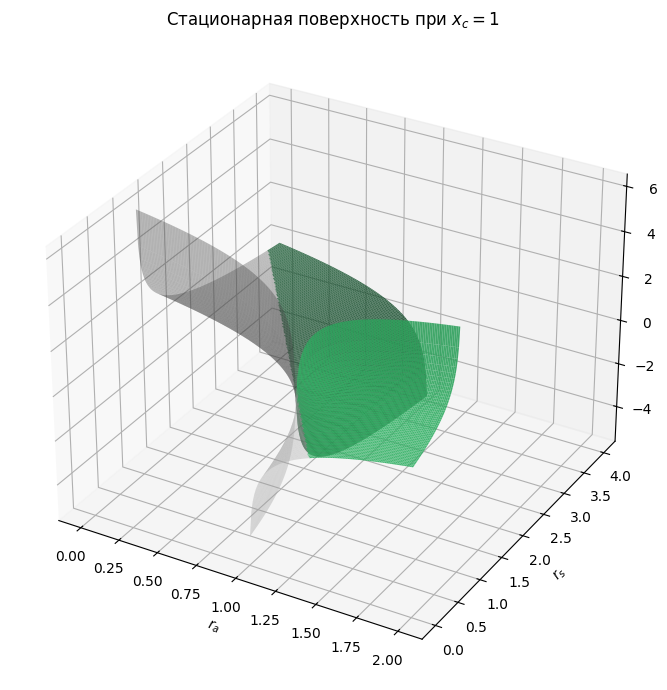

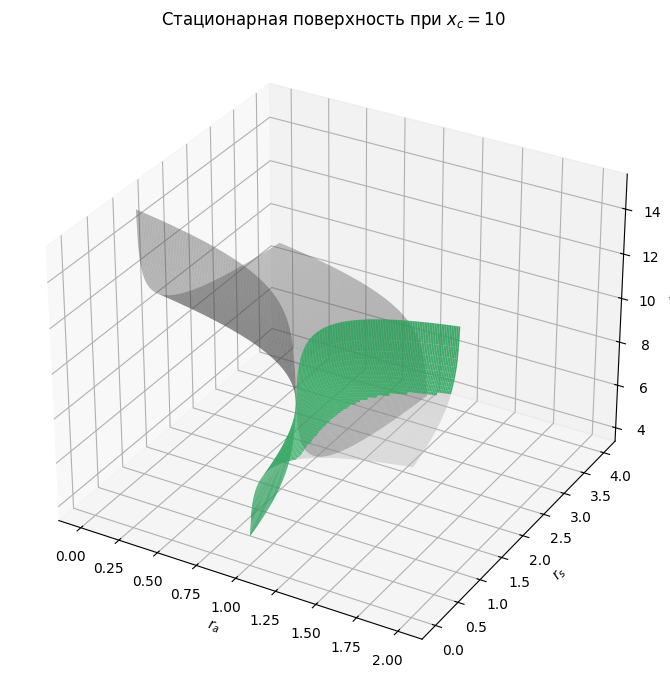

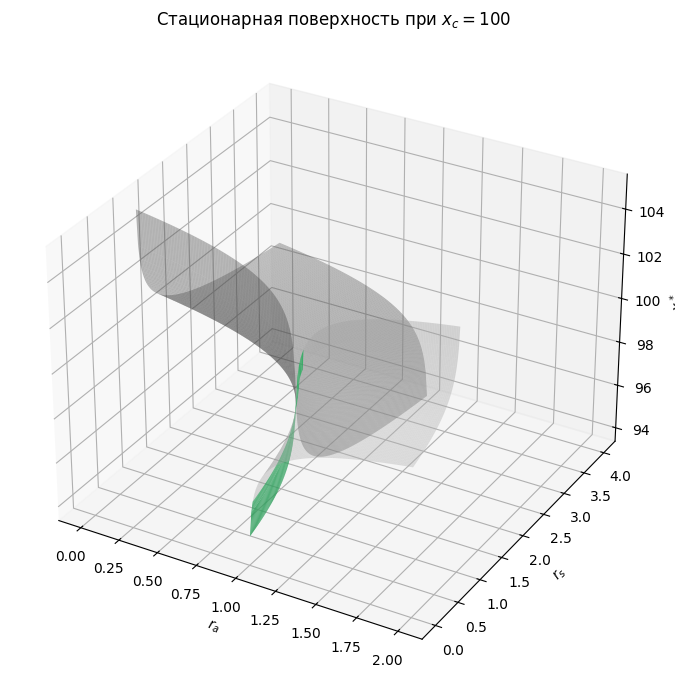

In [137]:
plot_3d_stationary_surface(xc=1)
plot_3d_stationary_surface(xc=10)
plot_3d_stationary_surface(xc=100)

In [5]:
from math import ceil

def S(x, xc):
    z = np.clip(xc - x, -700, 700)
    return 1.0 / (1.0 + np.exp(z))


def F(x, ra, rs, xc):
    s = S(x, xc)
    m = (1 - s) * ra + s * rs
    return m * x


def dF_dx(x, r_a, r_s, x_c):
    ex = np.exp(-x + x_c)
    return r_a*(1 - 1/(ex + 1)) + r_s/(ex + 1) + x*(-r_a*ex/(ex + 1)**2 + r_s*ex/(ex + 1)**2)

def _has_level(arr, level):
    amin = np.nanmin(arr)
    amax = np.nanmax(arr)
    return amin <= level <= amax


def plot_single_ra_x(ax, xc, rs, ra_range=(0.0, 2.0), x_range=(0.0, 50.0), n=500):
    ra = np.linspace(*ra_range, n)
    x = np.linspace(*x_range, n)
    RA, X = np.meshgrid(ra, x)

    G = X - F(X, RA, rs, xc)
    dF = dF_dx(X, RA, rs, xc)

    stable = (dF > -1) & (dF < 1)

    ax.contourf(
        RA, X, stable,
        levels=[0.5, 1],
        colors=["#ccffe5"],
        alpha=0.85
    )

    if _has_level(dF, -1):
        b = ax.contour(
            RA, X, dF,
            levels=[-1],
            colors="blue",
            linestyles="dashed",
            linewidths=1.8
        )
        ax.clabel(
        b,
        fmt={-1: "F`=-1"},
        inline=True,
        fontsize=8
        )

    if _has_level(dF, 1):
        r = ax.contour(
            RA, X, dF,
            levels=[1],
            colors="red",
            linestyles="dashed",
            linewidths=1.8
        )
        ax.clabel(
        r,
        fmt={1: "F`=1"},
        inline=True,
        fontsize=8
        )

    if _has_level(G, 0):
        c_stationary = ax.contour(
            RA, X, G,
            levels=[0],
            colors="black",
            linewidths=2
        )

        # подпись стационарной кривой
        mask = np.abs(G) < 0.01 * (x_range[1] - x_range[0])
        idx = np.argwhere(mask)
        if idx.size > 0:
            i, j = idx[len(idx) // 2]
            ax.text(
                RA[i, j],
                X[i, j],
                r"$x^*$",
                fontsize=11,
                ha="center",
                va="center",
                bbox=dict(facecolor="white", edgecolor="none", alpha=0.8, pad=0.25)
            )

    ax.set_title(rf"$x_c={xc},\ r_s={rs}$")
    ax.set_xlabel(r"$r_a$")
    ax.set_ylabel(r"$x$")
    ax.grid(True, linestyle=":", alpha=0.6)


def plot_stability_ra_x_grid(
    param_sets,
    ra_range=(0.0, 2.0),
    x_range=(0.0, 50.0),
    n=500,
    ncols=3,
    figsize_per_ax=(4, 4)
):
    """
    param_sets: список пар (xc, rs)
    Например: [(1, 0.8), (5, 0.8), (10, 1.2), (30, 1.2), (80, 1.8)]
    """
    nplots = len(param_sets)
    nrows = ceil(nplots / ncols)

    fig_w = figsize_per_ax[0] * ncols
    fig_h = figsize_per_ax[1] * nrows
    fig, axes = plt.subplots(nrows, ncols, figsize=(fig_w, fig_h), sharex=True, sharey=True)
    axes = np.atleast_1d(axes).ravel()

    for ax, (xc, rs) in zip(axes, param_sets):
        plot_single_ra_x(
            ax=ax,
            xc=xc,
            rs=rs,
            ra_range=ra_range,
            x_range=x_range,
            n=n
        )

    for k in range(nplots, len(axes)):
        axes[k].axis("off")

    plt.tight_layout()
    plt.show()

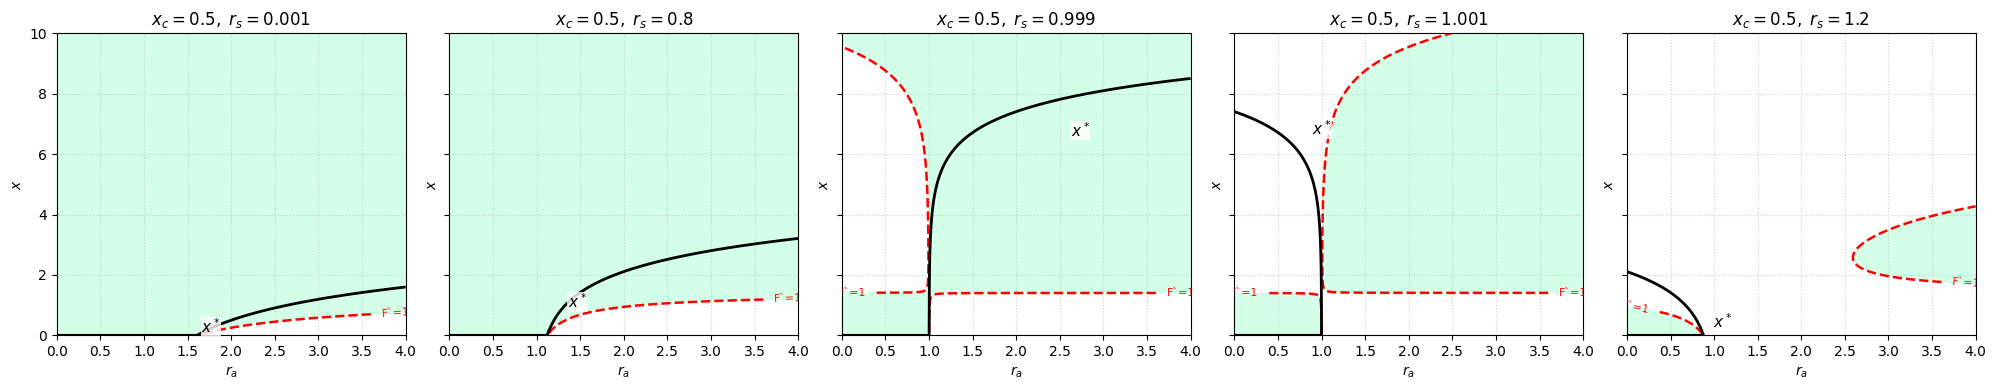

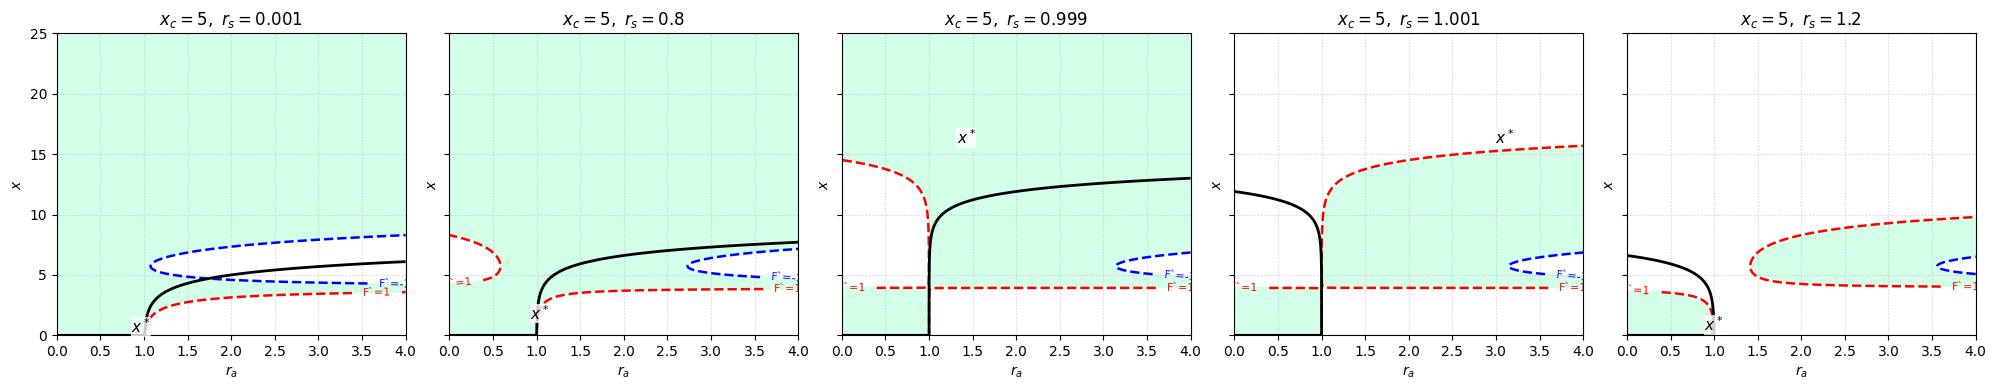

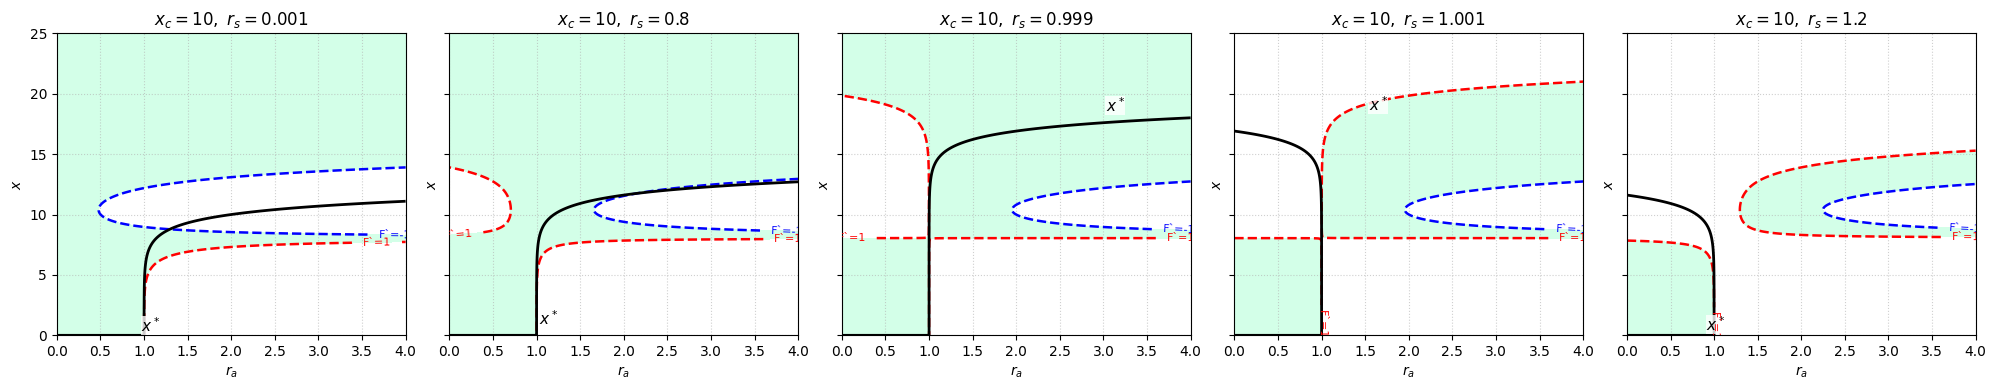

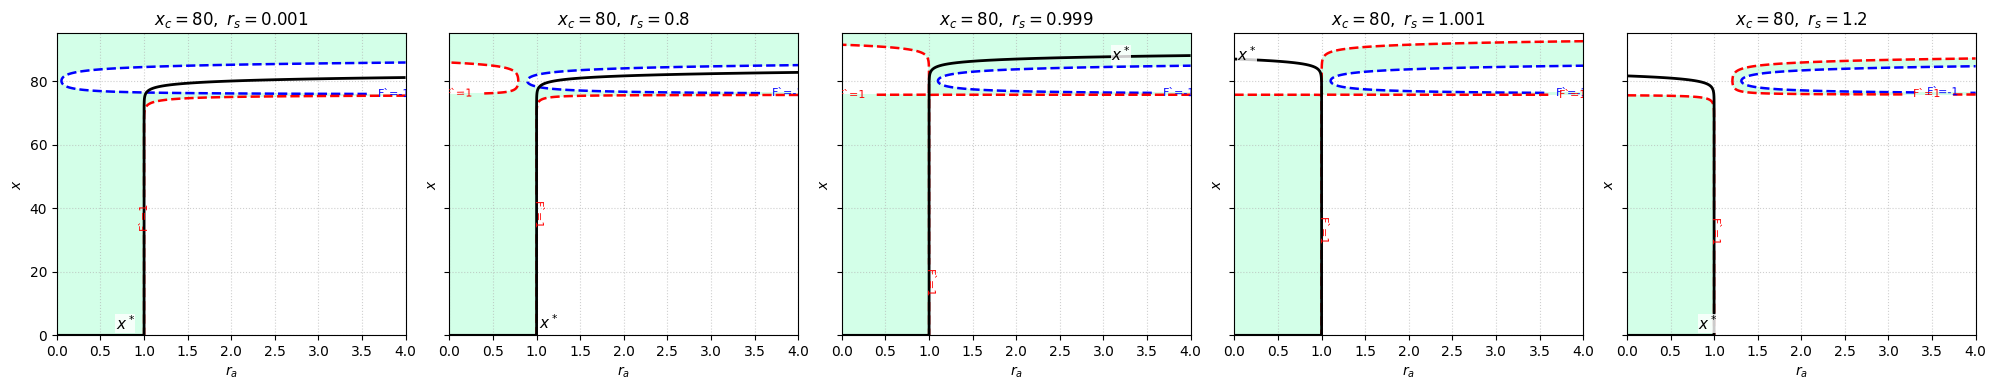

In [8]:
rs = [0.001, 0.8, 0.999, 1.001, 1.2]
param_sets = [(0.5, rs_i) for rs_i in rs]
plot_stability_ra_x_grid(
    param_sets=param_sets,
    ra_range=(0, 4),
    x_range=(0, 10),
    ncols=5
)

param_sets = [(5, rs_i) for rs_i in rs]
plot_stability_ra_x_grid(
    param_sets=param_sets,
    ra_range=(0, 4),
    x_range=(0, 25),
    ncols=5
)

param_sets = [(10, rs_i) for rs_i in rs]
plot_stability_ra_x_grid(
    param_sets=param_sets,
    ra_range=(0, 4),
    x_range=(0, 25),
    ncols=5
)

param_sets = [(80, rs_i) for rs_i in rs]
plot_stability_ra_x_grid(
    param_sets=param_sets,
    ra_range=(0, 4),
    x_range=(0, 95),
    ncols=5
)

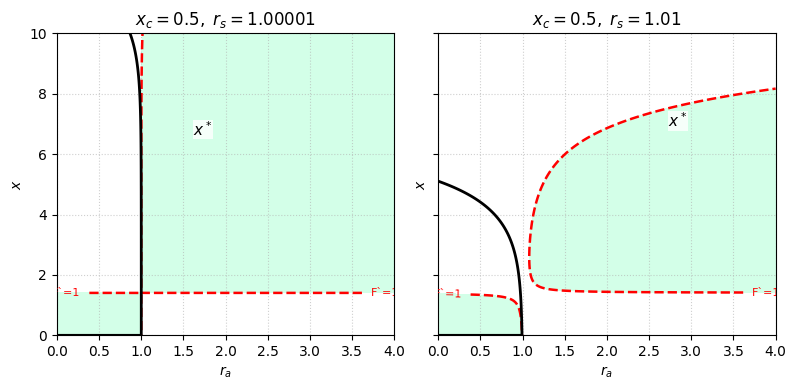

In [4]:
rs = [1.00001, 1.01]
param_sets = [(0.5, rs_i) for rs_i in rs]
plot_stability_ra_x_grid(
    param_sets=param_sets,
    ra_range=(0, 4),
    x_range=(0, 10),
    ncols=2
)

In [242]:
def f(x, xc):
    return 1.0 / (1.0 + np.exp(xc - x))
def m(x, N):
    return x / (N + x)
def Xn(x, r_s, r_a, xc = 5):
    F = f(x, xc)
    return ((1 - F) * r_a + F * r_s) * x

def r_tragectory(ax, xc_val, r_s, r_a, x0, num=125):
    xc = xc_val
    R = []
    X = []
    x = x0
    for n in range(num):
        x = Xn(x, r_s, r_a, xc)
        R.append(n)
        X.append(x)
    ax.plot(R, X, ls='', marker='.')
    ax.set_title(f'xc = {xc_val}, rs = {r_s}, ra = {r_a}, x_start = {x0}')
    ax.set_xlabel('$n$')
    ax.set_ylabel('$x_n$')

# В области стабильности точка одна

# Внутри синей пунктирной линии появляется мультистабильность или какая-то каша

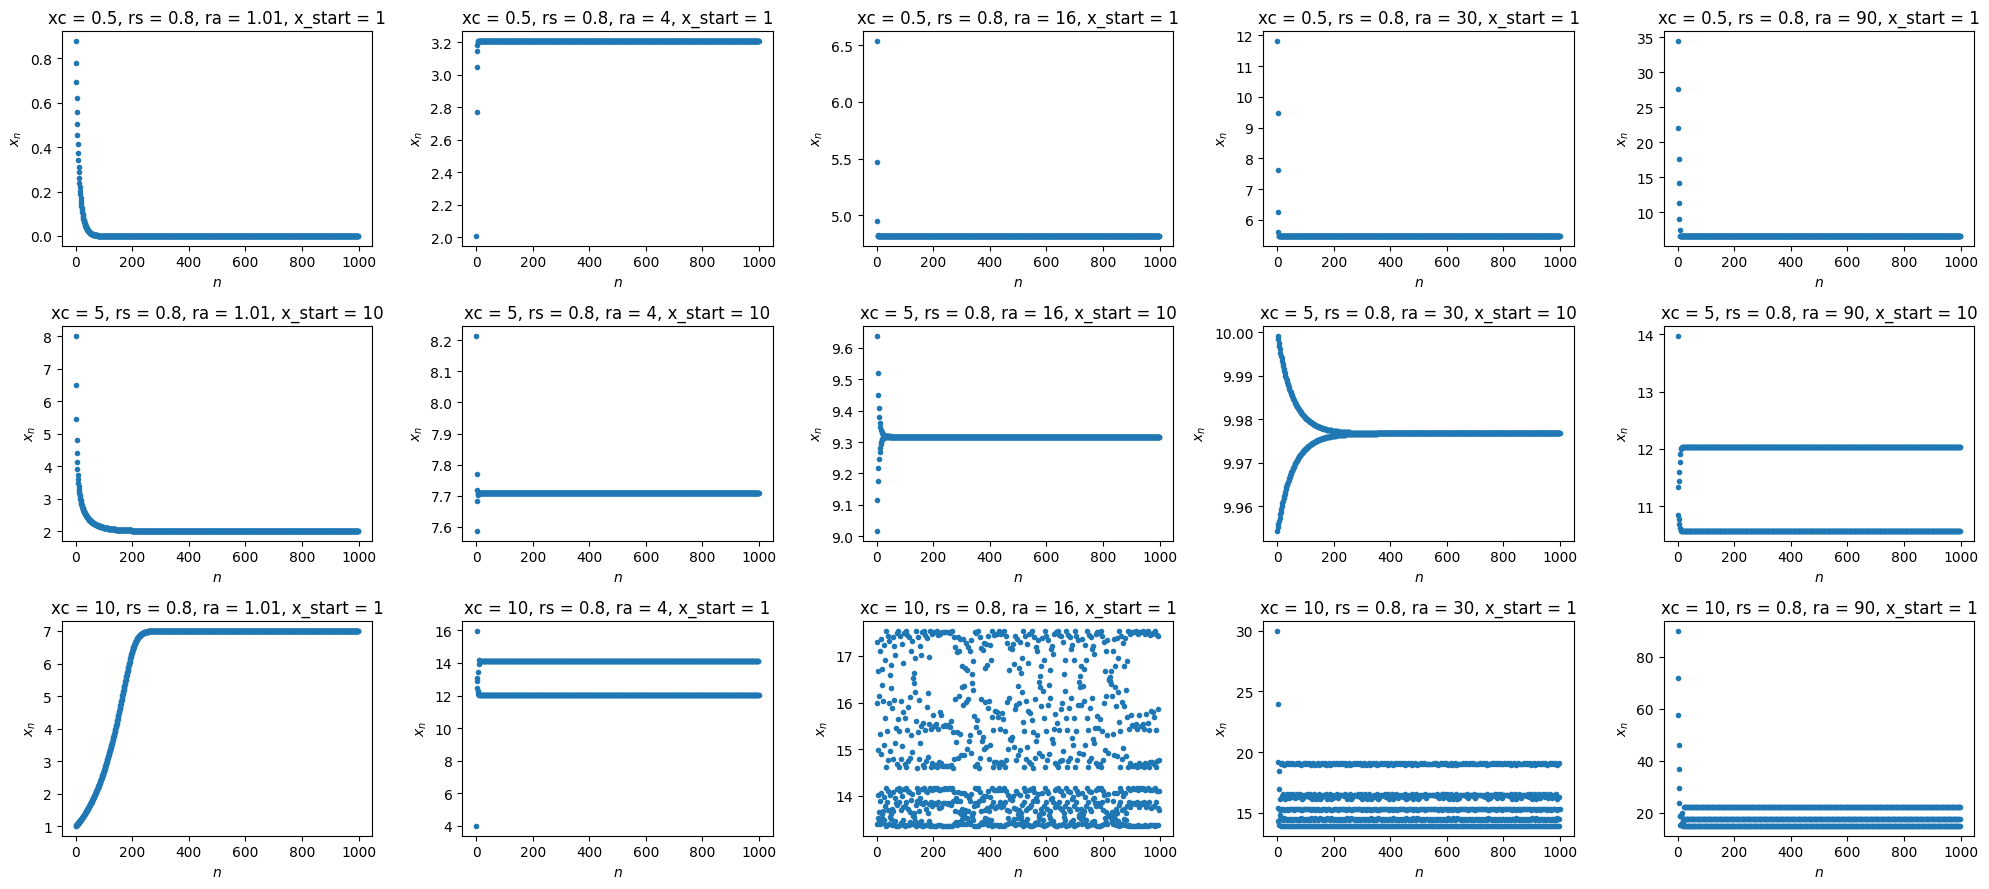

In [294]:
fig, axes = plt.subplots(3, 5, figsize=(20, 9))
r_a_values = [1.01, 4, 16, 30, 90]

for i, r_a in enumerate(r_a_values):
    r_tragectory(axes[1, i], 5, 0.8, r_a, 10, 1000)
for i, r_a in enumerate(r_a_values):
    r_tragectory(axes[2, i], 10, 0.8, r_a, 1, 1000)
for i, r_a in enumerate(r_a_values):
    r_tragectory(axes[0, i], 0.5, 0.8, r_a, 1, 1000)

plt.tight_layout()
plt.show()

# Как и знали раньше, при rs > 1, ra < 1 либо улетает в небо, либо вымирает

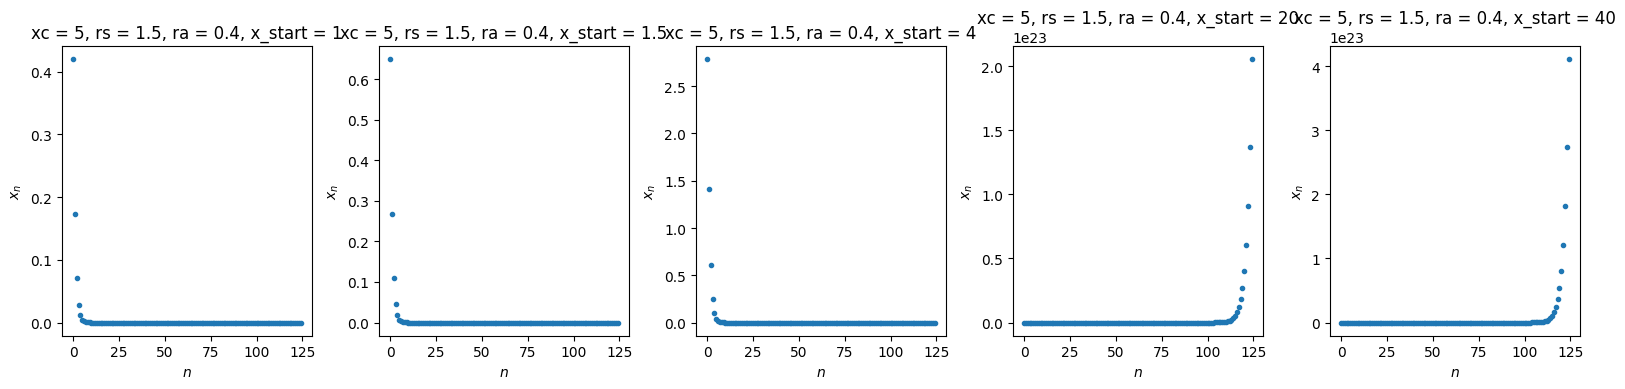

In [248]:
fig, axes = plt.subplots(1, 5, figsize=(16, 4))
x0_values = [1, 1.5, 4, 20, 40]

for i, x0 in enumerate(x0_values):
    r_tragectory(axes[i], 5, 1.5, 0.4, x0, 125)

plt.tight_layout()
plt.show()

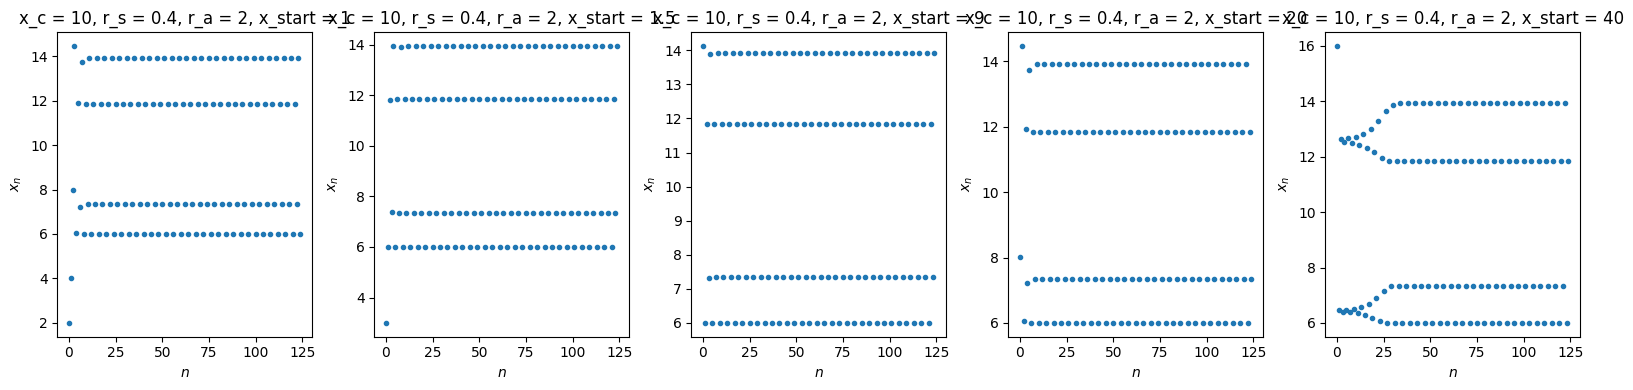

In [228]:
fig, axes = plt.subplots(1, 5, figsize=(16, 4))
x0_values = [1, 1.5, 9, 20, 40]

for i, x0 in enumerate(x0_values):
    r_tragectory(axes[i], 10, 0.4, 2, x0, 125)

plt.tight_layout()
plt.show()

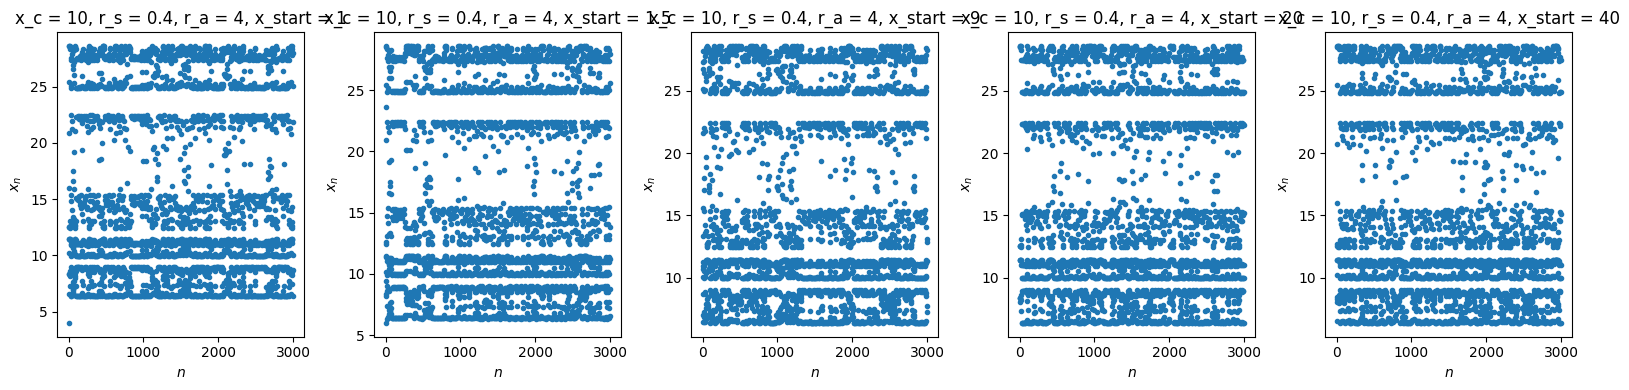

In [225]:
fig, axes = plt.subplots(1, 5, figsize=(16, 4))
x0_values = [1, 1.5, 9, 20, 40]

for i, x0 in enumerate(x0_values):
    r_tragectory(axes[i], 10, 0.4, 4, x0, 3000)

plt.tight_layout()
plt.show()

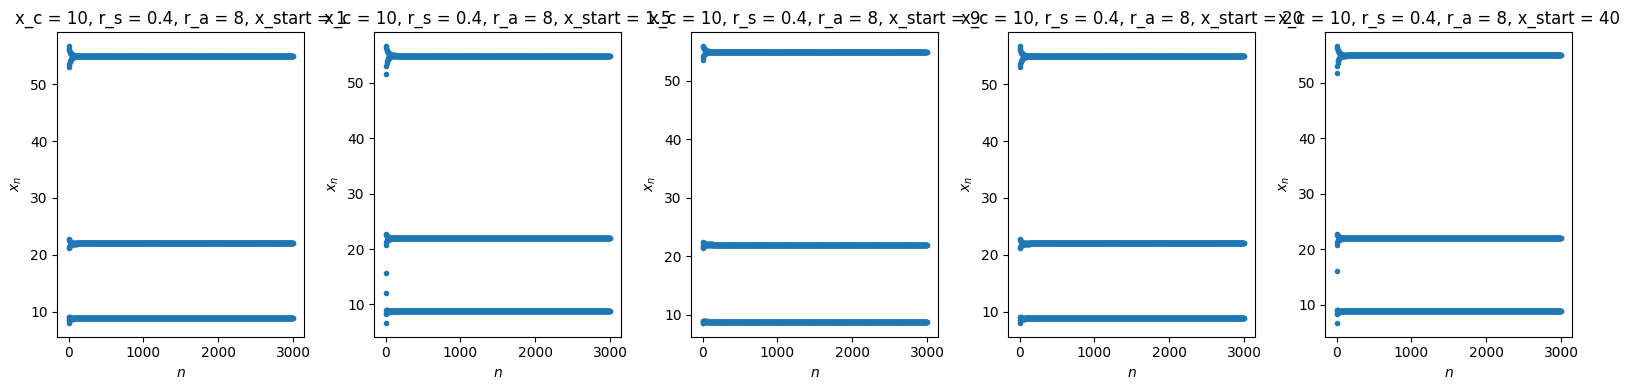

In [229]:
fig, axes = plt.subplots(1, 5, figsize=(16, 4))
x0_values = [1, 1.5, 9, 20, 40]

for i, x0 in enumerate(x0_values):
    r_tragectory(axes[i], 10, 0.4, 8, x0, 3000)

plt.tight_layout()
plt.show()

In [9]:
def F_map(x, r_a, r_s, x_c):
    z = np.clip(x_c - x, -50, 50)
    S = 1.0 / (1.0 + np.exp(z))
    return x * ((1 - S) * r_a + S * r_s)


def bifurcation_rs(
    ax,
    x_c,
    r_a,
    r_s_min=0.0,
    r_s_max=1.0,
    x0=1.0,
    n_transient=1000,
    n_plot=300,
    n_r=100
):
    r_s_values = np.linspace(r_s_min, r_s_max, n_r)

    R, X = [], []

    for r_s in r_s_values:
        x = x0
        for _ in range(n_transient):
            x = F_map(x, r_a, r_s, x_c)
            if not np.isfinite(x) or abs(x) > 1e6:
                break
        for _ in range(n_plot):
            x = F_map(x, r_a, r_s, x_c)
            if not np.isfinite(x) or abs(x) > 1e6:
                break
            R.append(r_s)
            X.append(x)

    ax.plot(R, X, ',', alpha=0.35)
    ax.set_xlabel(r"$r_s$")
    ax.set_ylabel(r"$x$")
    ax.set_title(rf"$x_c={x_c},\; r_a={r_a}$")
    ax.grid(alpha=0.3)

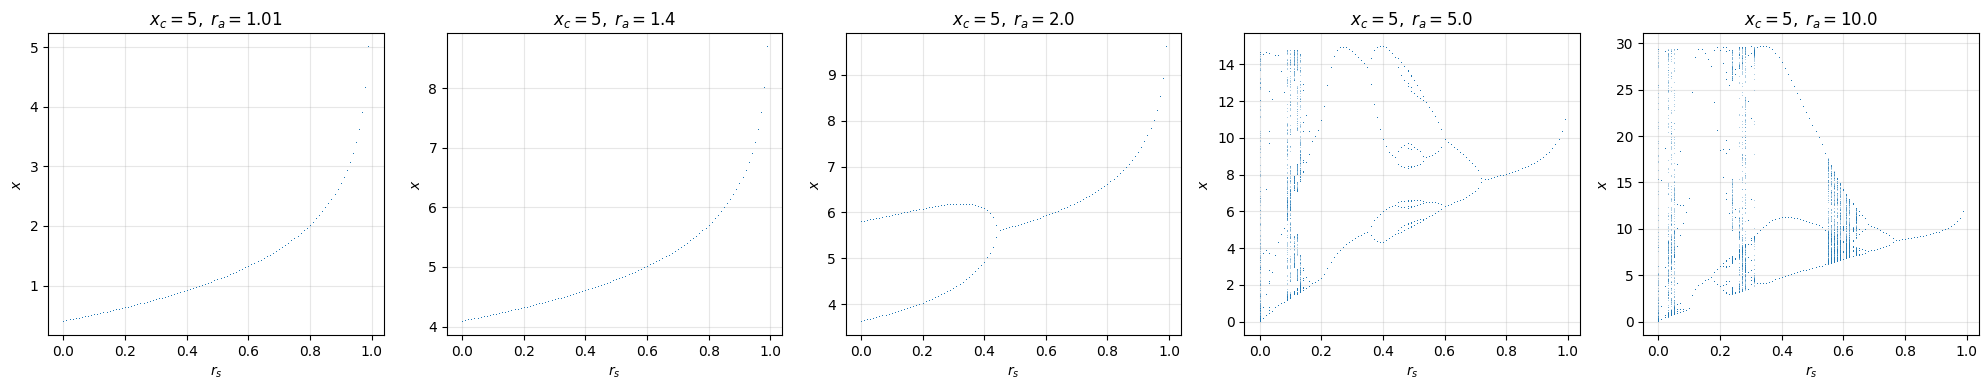

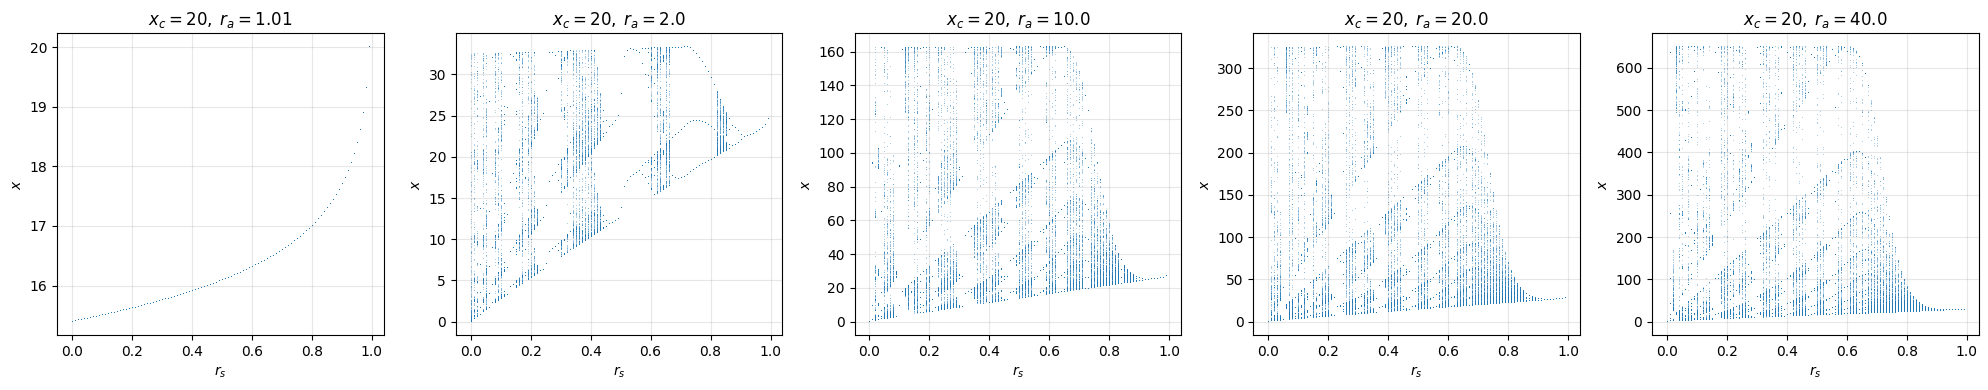

In [10]:
fig, axes = plt.subplots(1, 5, figsize=(20, 4))

x_c = 5
r_a_values = [1.01, 1.4, 2.0, 5.0, 10.0]   # r_a > 1

for ax, r_a in zip(axes, r_a_values):
    bifurcation_rs(
        ax=ax,
        x_c=x_c,
        r_a=r_a,
        r_s_min=0.0,
        r_s_max=0.99,   # r_s < 1
        x0=2.0
    )

plt.tight_layout()
plt.show()
fig, axes = plt.subplots(1, 5, figsize=(20, 4))

x_c = 20
r_a_values = [1.01, 2.0, 10.0, 20.0, 40.0]   # r_a > 1

for ax, r_a in zip(axes, r_a_values):
    bifurcation_rs(
        ax=ax,
        x_c=x_c,
        r_a=r_a,
        r_s_min=0.0,
        r_s_max=0.99,   # r_s < 1
        x0=2.0
    )

plt.tight_layout()
plt.show()

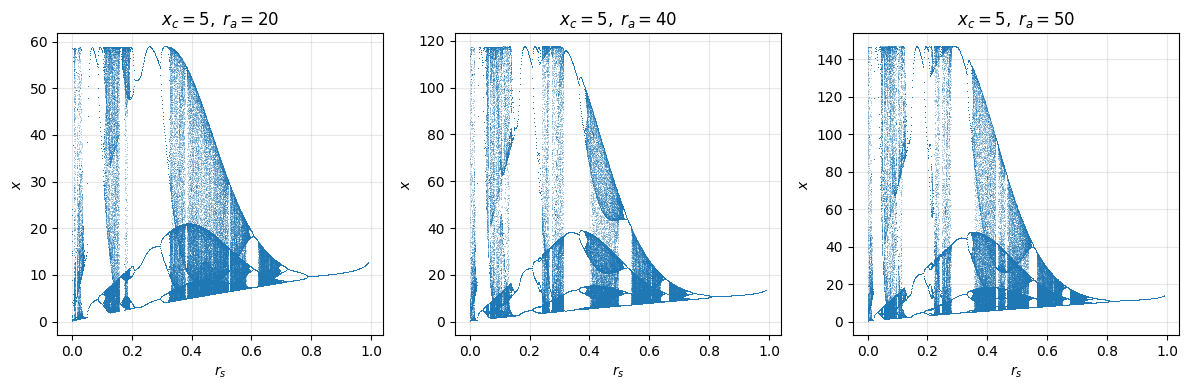

In [283]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

x_c = 5
r_a_values = [20, 40, 50]   # r_a > 1

for ax, r_a in zip(axes, r_a_values):
    bifurcation_rs(
        ax=ax,
        x_c=x_c,
        r_a=r_a,
        r_s_min=0.0,
        r_s_max=0.99,   # r_s < 1
        x0=2.0
    )

plt.tight_layout()
plt.show()

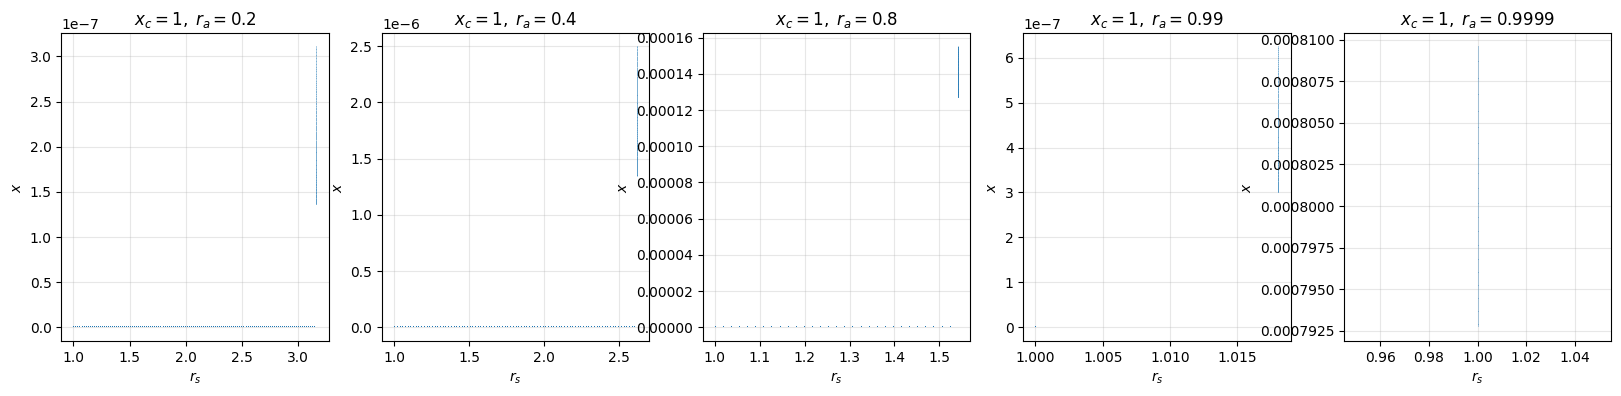

In [13]:
fig, axes = plt.subplots(1, 5, figsize=(20, 4))

x_c = 1
r_a_values = [0.2, 0.4, 0.8, 0.99, 0.9999]   # r_a > 1

for ax, r_a in zip(axes, r_a_values):
    bifurcation_rs(
        ax=ax,
        x_c=x_c,
        r_a=r_a,
        r_s_min=1.00001,
        r_s_max=10,
        x0=0.001
    )

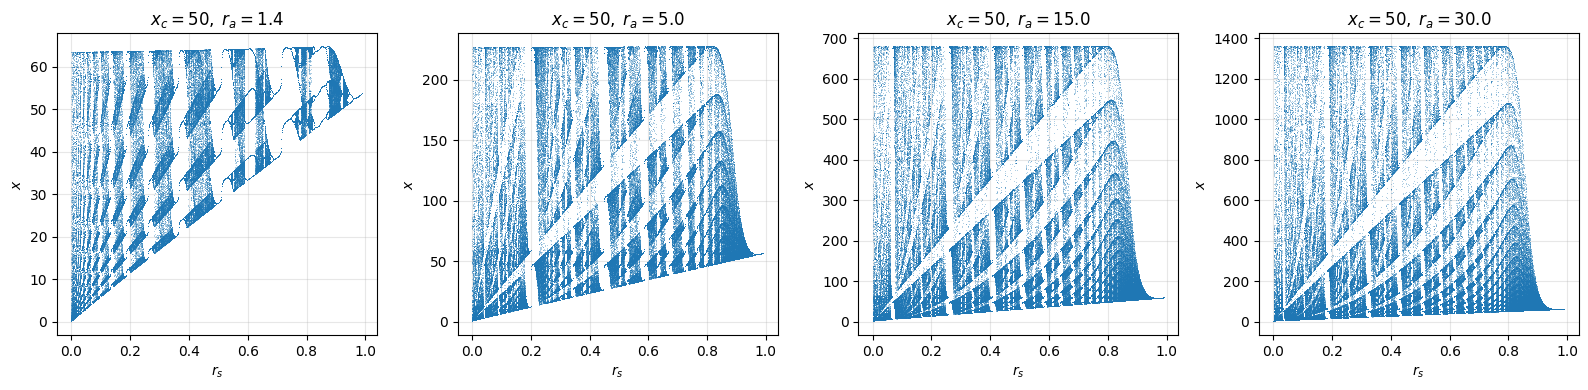

In [288]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))

x_c = 50
r_a_values = [1.4, 5.0, 15.0, 30.0]   # r_a > 1

for ax, r_a in zip(axes, r_a_values):
    bifurcation_rs(
        ax=ax,
        x_c=x_c,
        r_a=r_a,
        r_s_min=0.0,
        r_s_max=0.99,   # r_s < 1
        x0=2.0
    )

plt.tight_layout()
plt.show()

In [278]:
def bifurcation_ra(
    ax,
    x_c,
    r_s,
    r_a_min=0.5,
    r_a_max=5.0,
    x0=1.0,
    n_transient=3000,
    n_plot=300,
    n_r=1000
):
    r_a_values = np.linspace(r_a_min, r_a_max, n_r)

    R, X = [], []

    for r_a in r_a_values:
        x = x0

        # выход на аттрактор
        for _ in range(n_transient):
            x = F_map(x, r_a, r_s, x_c)
            if not np.isfinite(x) or abs(x) > 1e6:
                break

        # сбор точек
        for _ in range(n_plot):
            x = F_map(x, r_a, r_s, x_c)
            if not np.isfinite(x) or abs(x) > 1e6:
                break
            R.append(r_a)
            X.append(x)

    ax.plot(R, X, ',', alpha=0.35)
    ax.set_xlabel(r"$r_a$")
    ax.set_ylabel(r"$x$")
    ax.set_title(rf"$x_c={x_c},\; r_s={r_s}$")
    ax.grid(alpha=0.3)

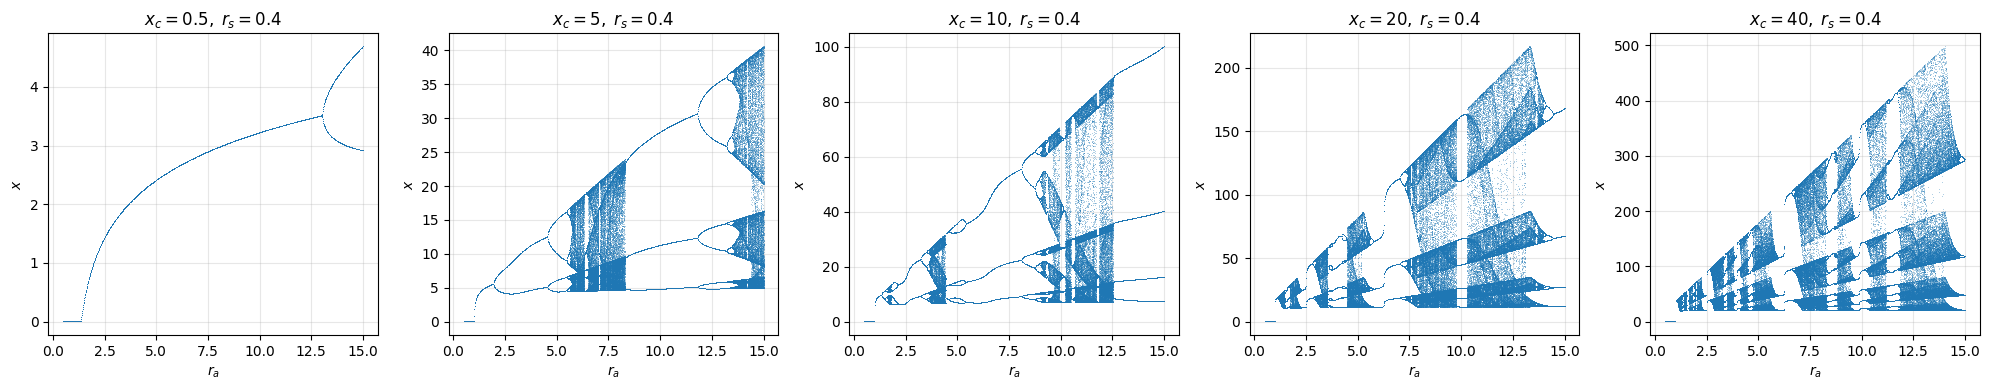

In [279]:
fig, axes = plt.subplots(1, 5, figsize=(20, 4))

x_c = [0.5, 5, 10, 20, 40]
r_s = 0.4
ra_min, ra_max = 0.5, 15.0

for ax, xc in zip(axes, x_c):
    bifurcation_ra(
        ax=ax,
        x_c=xc,
        r_s=r_s,
        r_a_min=ra_min,
        r_a_max=ra_max,
        x0=2.0
    )

plt.tight_layout()
plt.show()

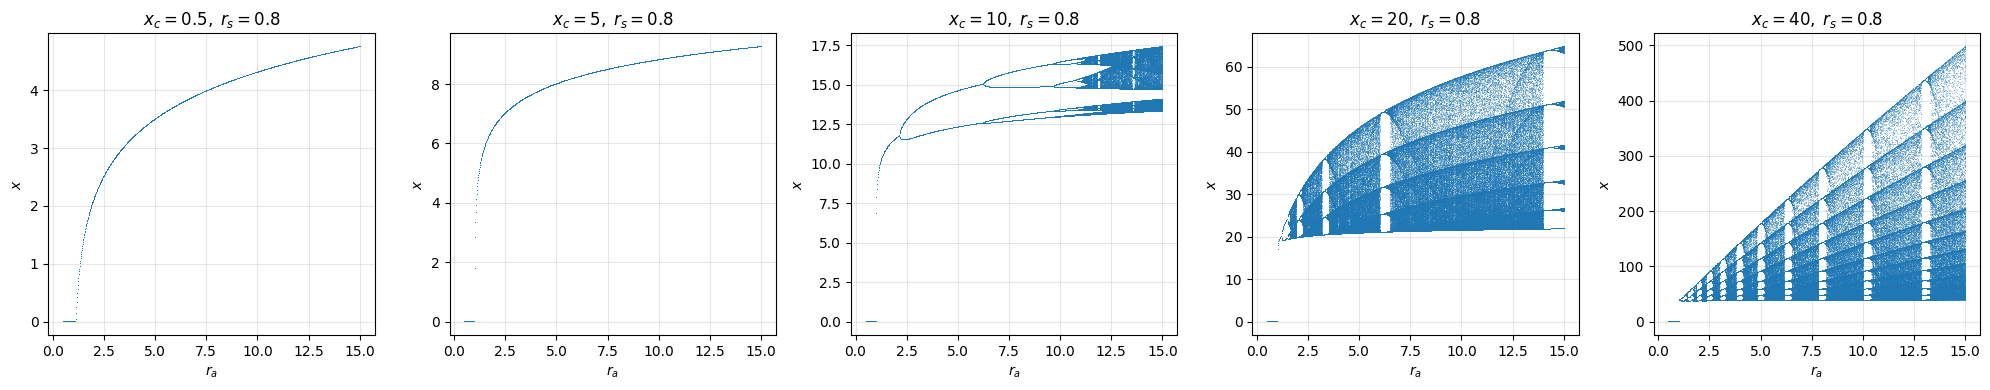

In [282]:
fig, axes = plt.subplots(1, 5, figsize=(20, 4))

x_c = [0.5, 5, 10, 20, 40]
r_s = 0.8
ra_min, ra_max = 0.5, 15.0

for ax, xc in zip(axes, x_c):
    bifurcation_ra(
        ax=ax,
        x_c=xc,
        r_s=r_s,
        r_a_min=ra_min,
        r_a_max=ra_max,
        x0=2.0
    )

plt.tight_layout()
plt.show()

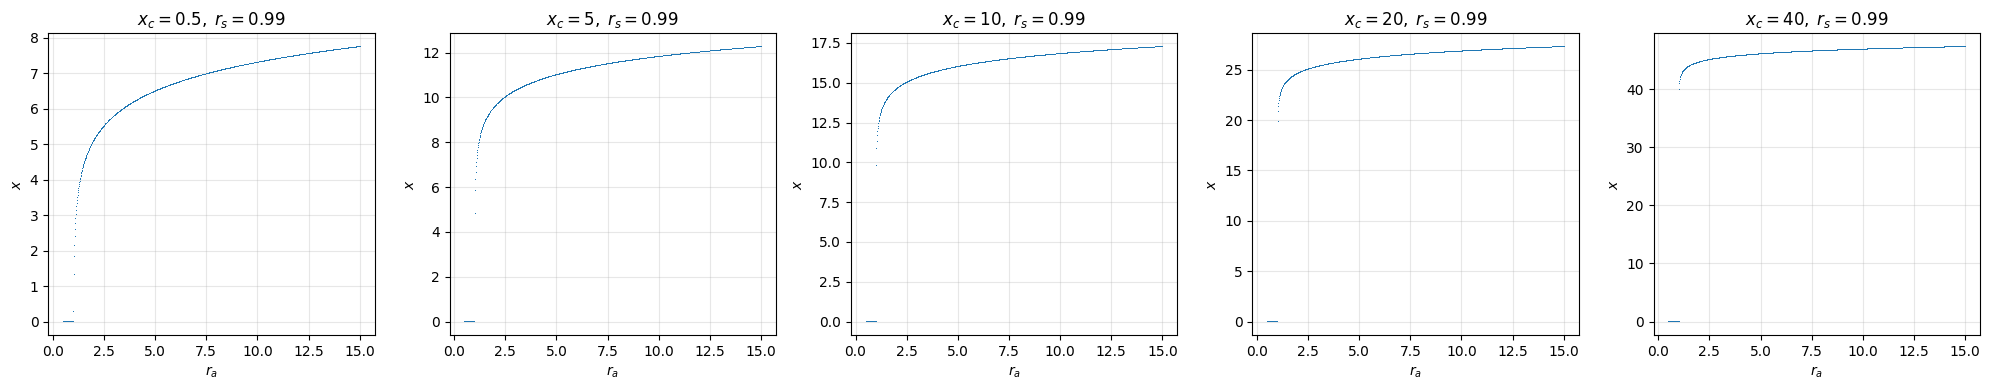

In [291]:
fig, axes = plt.subplots(1, 5, figsize=(20, 4))

x_c = [0.5, 5, 10, 20, 40]
r_s = 0.99
ra_min, ra_max = 0.5, 15.0

for ax, xc in zip(axes, x_c):
    bifurcation_ra(
        ax=ax,
        x_c=xc,
        r_s=r_s,
        r_a_min=ra_min,
        r_a_max=ra_max,
        x0=2.0
    )

plt.tight_layout()
plt.show()